In [20]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.5 * nS 
g_AMPA_rec_E = 5.5 * nS 
g_AMPA_ext_I = 5.5 * nS
g_AMPA_rec_I = 5.5 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

recurrent_radius = 2  


def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,input_freq=40):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    V_thr_E : volt
    tau_rp_E_var : second
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr_E', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory='tau_rp_E_var', method='euler',name='P_E')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.35  
    P_E.k_GABA_E_hsp = 0.35  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  
    P_E.V_thr_E = V_thr
    P_E.tau_rp_E_var = tau_rp_E

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler',name='P_I')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=input_freq * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.1 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.52, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.9#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I Na blocker so 0.40 to 38
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E Na blocker so 0.32 to 0.3


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

   
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')

    r_est_mon = StateMonitor(P_E, variables=['r_est'], record=[45], name = 'r_est',dt=record_dt)

    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



# def show_rand_rate(net, show_time = 1000*ms):
#     N_inp=net['inp'].N
#     rates = np.random.normal(loc=40, scale=0, size=N_inp)
#     rate_img = np.clip(rates, 5, 50)*Hz
#     net['inp'].rates = rate_img
#     net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,input_freq=40,show_time = 1000*ms):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA,input_freq=input_freq)
    net.run(show_time, report = 'text')
    # show_rand_rate(net,show_time=show_time)
    return net



In [21]:
start_scope()
seed(123)
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=50*second,
              tau_int_AMPA=50*second,
              tau_ins_GABA=50*second,
              tau_int_GABA=50*second,
              show_time=15000*second)

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Starting simulation at t=0. s for a duration of 15. ks
172.796 s (1%) simulated in 10s, estimated 14m 18s remaining.
0.351507 ks (2%) simulated in 20s, estimated 13m 53s remaining.
0.51153 ks (3%) simulated in 30s, estimated 14m 10s remaining.
0.694262 ks (4%) simulated in 40s, estimated 13m 44s remaining.
0.875049 ks (5%) simulated in 50s, estimated 13m 27s remaining.
1.038775 ks (6%) simulated in 1m 0s, estimated 13m 26s remaining.
1.223101 ks (8%) simulated in 1m 10s, estimated 13m 8s remaining.
1.407063 ks (9%) simulated in 1m 20s, estimated 12m 53s remaining.
1.590973 ks (10%) simulated in 1m 30s, estimated 12m 39s remaining.
1.753592 ks (11%) simulated in 1m 40s, estimated 12m 35s remaining.
1.936487 ks (12%) simulated in 1m 50s, estimated 12m 22s remaining.
2.120824 ks (14%) simulated in 2m 0s, estimated 12m 9s remaining.
2.282702 ks (15%) simulated in 2m 10s, estimated 12m 4s remaining.
2.465096 

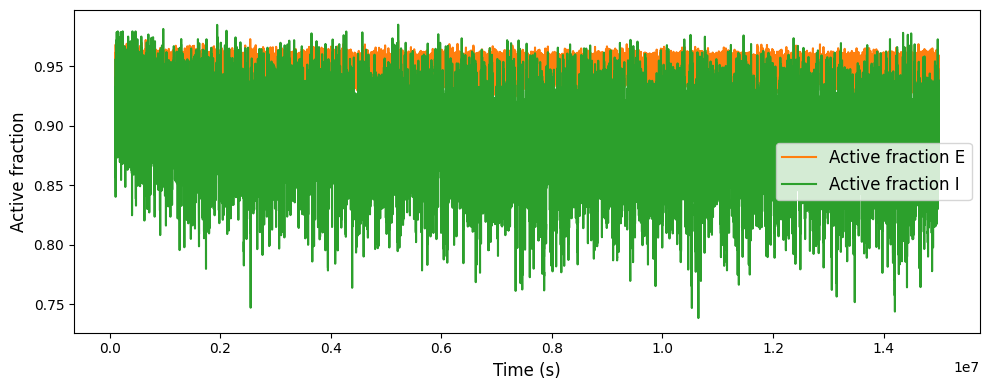

In [22]:
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']

plt.figure(figsize=(10, 4))
plt.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction E')
plt.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction I')
plt.xlabel('Time (s)',fontsize=12)
plt.ylabel('Active fraction',fontsize=12)
plt.legend(loc=5,fontsize=12)
plt.tight_layout()

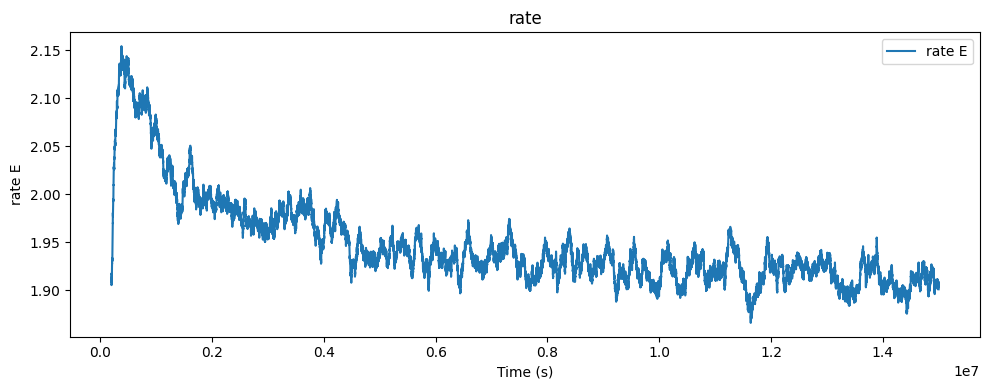

In [23]:
r_est_E = net['rate_pop_mon_E']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[1000:]/ms, r_est_E.r_pop_E[0,1000:]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

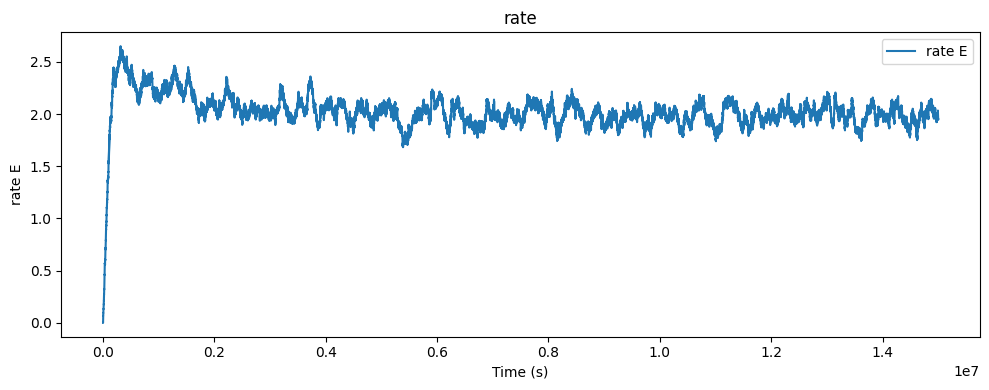

In [24]:
r_est_E = net['r_est']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t/ms, r_est_E.r_est[0]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

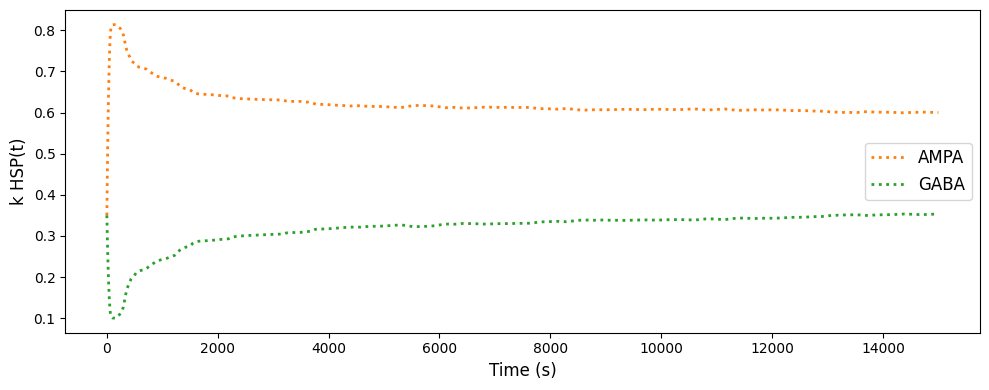

In [25]:
kAMPA_mon_E=net['k_AMPA_E_hsp']
kGABA_mon_E=net['k_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(kAMPA_mon_E.t/second, kAMPA_mon_E.k_AMPA_E_hsp[45], label='AMPA',color='tab:orange',linestyle=':',linewidth=2)
plt.plot(kGABA_mon_E.t/second, kGABA_mon_E.k_GABA_E_hsp[45], label='GABA',color='tab:green',linestyle=':',linewidth=2)
plt.xlabel('Time (s)',fontsize=12)
plt.ylabel('k HSP(t)',fontsize=12)
#plt.title('Homeostatic Synaptic Scaling')
plt.legend(loc=5,fontsize=12)
plt.tight_layout()

In [26]:
net.store('baseline',filename='baseline_2hz.bri')

In [2]:
net = run_sim(tau_ins_AMPA=50*second,
              tau_int_AMPA=50*second,
              tau_ins_GABA=50*second,
              tau_int_GABA=50*second,
              show_time=0*second)

INFO:root:creating /tmp/brian_flag_test_1gr3v4ob/tmp
INFO:root:creating /tmp/brian_flag_test_1gr3v4ob/tmp/brian_flag_test_1gr3v4ob
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_1gr3v4ob/flag_test.cpp -o /tmp/brian_flag_test_1gr3v4ob/tmp/brian_flag_test_1gr3v4ob/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_yd6lwh8u/tmp
INFO:root:creating /tmp/brian_flag_test_yd6lwh8u/tmp/brian_flag_test_yd6lwh8u
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_yd6lwh8u/flag_test.cpp -o /tmp/brian_flag_test_yd6lwh8u/tmp/brian_flag_test_yd6lwh8u/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_t91zo4ac/tmp
INFO:root:creating /tmp/brian_flag_test_t91zo4ac/tmp/brian_flag_test_t91zo4ac
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_t91zo4ac/flag_test.cpp -o /tmp/brian_flag_test_t9

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


In [3]:
net.restore('baseline', filename='baseline_2hz.bri')

In [29]:
def run_full_hsp_trajectory(net, alpha=1.0, run_time=2000*second,
                            analysis_start_s=15000.0,input_freq=40*Hz,
                            tau_ins_AMPA=100*second,
                            tau_int_AMPA=50*second,
                            tau_ins_GABA=100*second,
                            tau_int_GABA=50*second,
                            neuron_idx=45, benzo=False,Nablocker=False):

    #net.restore('baseline')
    net.restore('baseline', filename='baseline_2hz.bri')
    inp = net['inp']
    inp.rates=input_freq
    P_E = net['P_E']
    PG_E = net['PG_E']

    gAMPA_mon_E = net['k_AMPA_E_hsp']
    gGABA_mon_E = net['k_GABA_E_hsp']
    r_est_mon = net['r_est']   # StateMonitor on neuron 45 in your build_network

    baseline_w = float(PG_E.w[0])
    PG_E.w[:] = alpha * baseline_w

    P_E.tau_ins_AMPA_E = tau_ins_AMPA
    P_E.tau_int_AMPA_E = tau_int_AMPA
    P_E.tau_ins_GABA_E = tau_ins_GABA
    P_E.tau_int_GABA_E = tau_int_GABA

    if Nablocker:
        P_E.V_thr_E = -48*mV      # Na blocker-like: harder to spike
        P_E.tau_rp_E_var = 3*ms       # Na blocker-like: longer recovery

    if benzo:
        net['P_E'].k_GABA_E_hsp = 1.0
        net['P_E'].tau_ins_GABA_E = 1e99 * second
        net['P_E'].tau_int_GABA_E = 1e99 * second

    net.run(run_time, report='text')

    # Use the SAME monitor timebase as r_est_mon
    t_all = np.array(r_est_mon.t / second)
    mask = t_all >= analysis_start_s

    return {
        't': t_all[mask],
        'r_est_trace': np.array(r_est_mon.r_est[0, mask] / Hz),   # neuron 45
        'kE_trace': np.array(gAMPA_mon_E.k_AMPA_E_hsp[neuron_idx, mask]),
        'kI_trace': np.array(gGABA_mon_E.k_GABA_E_hsp[neuron_idx, mask]),
    }

In [27]:
seed(123)
res_trace = run_full_hsp_trajectory(
    net,
    alpha=1,
    run_time=5000*second,
    input_freq=35*Hz,
    analysis_start_s=15000.0,
    tau_ins_AMPA=50.0*second,
    tau_int_AMPA=50.0*second,
    tau_ins_GABA=50.0*second,
    tau_int_GABA=50.0*second,
    neuron_idx=45, Nablocker=False
)

t = res_trace['t']
r_est_trace = res_trace['r_est_trace']
kE_trace = res_trace['kE_trace']
kI_trace = res_trace['kI_trace']

Starting simulation at t=15. ks for a duration of 5. ks
168.581 s (3%) simulated in 10s, estimated 4m 47s remaining.
0.325202 ks (6%) simulated in 20s, estimated 4m 48s remaining.
0.50134 ks (10%) simulated in 30s, estimated 4m 29s remaining.
0.674571 ks (13%) simulated in 40s, estimated 4m 16s remaining.
0.848401 ks (16%) simulated in 50s, estimated 4m 5s remaining.
1.001475 ks (20%) simulated in 1m 0s, estimated 4m 0s remaining.
1.175657 ks (23%) simulated in 1m 10s, estimated 3m 48s remaining.
1.349855 ks (26%) simulated in 1m 20s, estimated 3m 36s remaining.
1.502638 ks (30%) simulated in 1m 30s, estimated 3m 29s remaining.
1.677378 ks (33%) simulated in 1m 40s, estimated 3m 18s remaining.
1.833555 ks (36%) simulated in 1m 50s, estimated 3m 10s remaining.
1.967134 ks (39%) simulated in 2m 0s, estimated 3m 5s remaining.
2.118461 ks (42%) simulated in 2m 10s, estimated 2m 57s remaining.
2.281656 ks (45%) simulated in 2m 20s, estimated 2m 47s remaining.
2.456383 ks (49%) simulated in 

In [30]:
from scipy.signal import welch
import numpy as np
import matplotlib.pyplot as plt
from brian2 import *

def compute_r_est_spectrum(t, r, fmax=0.2):
    """
    t in seconds, r in Hz.
    Returns frequencies and power spectrum.
    """
    dt = np.median(np.diff(t))
    fs = 1.0 / dt

    r = np.asarray(r)
    r = r - np.mean(r)   # remove DC/steady component

    freqs, power = welch(
        r,
        fs=fs,
        nperseg=min(2048, len(r)),
        noverlap=None,
        detrend='constant'
    )

    keep = freqs <= fmax
    return freqs[keep], power[keep]


def run_input_frequency_sweep_regular(
    net,
    input_freqs_hz,
    run_time=5000*second,
    analysis_start_s=15000.0,
    alpha=1.0,
    neuron_idx=45,
    fmax=0.2,
    benzo=False,
    Nablocker=False,
    save_traces=True):

    spectra = []
    freqs_ref = None
    mean_r_est = []
    time_series = {}

    for f_in in input_freqs_hz:
        print(f"\nRunning input frequency = {f_in:.2f} Hz")

        res = run_full_hsp_trajectory(
            net,
            alpha=alpha,
            run_time=run_time,
            input_freq=f_in*Hz,
            analysis_start_s=analysis_start_s,
            tau_ins_AMPA=50.0*second,
            tau_int_AMPA=50.0*second,
            tau_ins_GABA=50.0*second,
            tau_int_GABA=50.0*second,
            neuron_idx=neuron_idx,
            benzo=benzo,
            Nablocker=Nablocker
        )

        
        t = res["t"]
        mask = t >= analysis_start_s
        t=t[mask]
        r = res["r_est_trace"]
        r=r[mask]
        if save_traces:
            time_series[float(f_in)] = {
                "t": t.copy(),
                "r_est": r.copy()
            }

        if len(t) < 20:
            raise ValueError(
                f"Trace too short for input {f_in} Hz. "
                "Decrease analysis_start_s or increase run_time."
            )

        freqs, power = compute_r_est_spectrum(t, r, fmax=fmax)

        if freqs_ref is None:
            freqs_ref = freqs
        else:
            power = np.interp(freqs_ref, freqs, power)

        spectra.append(power)
        mean_r_est.append(np.mean(r))

    spectra = np.array(spectra).T
    mean_r_est = np.array(mean_r_est)

    return {
        "input_freqs_hz": np.array(input_freqs_hz),
        "spectral_freqs_hz": freqs_ref,
        "power": spectra,
        "mean_r_est": mean_r_est,
        "time_series": time_series
    }

In [31]:
seed(123)

input_freqs_hz = np.linspace(30, 40, 11) #25,45,41

sweep_regular = run_input_frequency_sweep_regular(
    net,
    input_freqs_hz=input_freqs_hz,
    run_time=5000*second,
    analysis_start_s=15000.0,
    alpha=1.0,
    neuron_idx=45,
    fmax=0.1,
    benzo=False,
    save_traces=True,
    Nablocker=False,
)


Running input frequency = 30.00 Hz
Starting simulation at t=15. ks for a duration of 5. ks
136.564 s (2%) simulated in 10s, estimated 5m 56s remaining.
294.178 s (5%) simulated in 20s, estimated 5m 20s remaining.
0.429383 ks (8%) simulated in 30s, estimated 5m 19s remaining.
0.594612 ks (11%) simulated in 40s, estimated 4m 56s remaining.
0.740914 ks (14%) simulated in 50s, estimated 4m 47s remaining.
0.906199 ks (18%) simulated in 1m 0s, estimated 4m 31s remaining.
1.067367 ks (21%) simulated in 1m 10s, estimated 4m 18s remaining.
1.20768 ks (24%) simulated in 1m 20s, estimated 4m 11s remaining.
1.362352 ks (27%) simulated in 1m 30s, estimated 4m 0s remaining.
1.502384 ks (30%) simulated in 1m 40s, estimated 3m 53s remaining.
1.631291 ks (32%) simulated in 1m 50s, estimated 3m 47s remaining.
1.779069 ks (35%) simulated in 2m 0s, estimated 3m 37s remaining.
1.925044 ks (38%) simulated in 2m 10s, estimated 3m 28s remaining.
2.064018 ks (41%) simulated in 2m 20s, estimated 3m 19s remaini

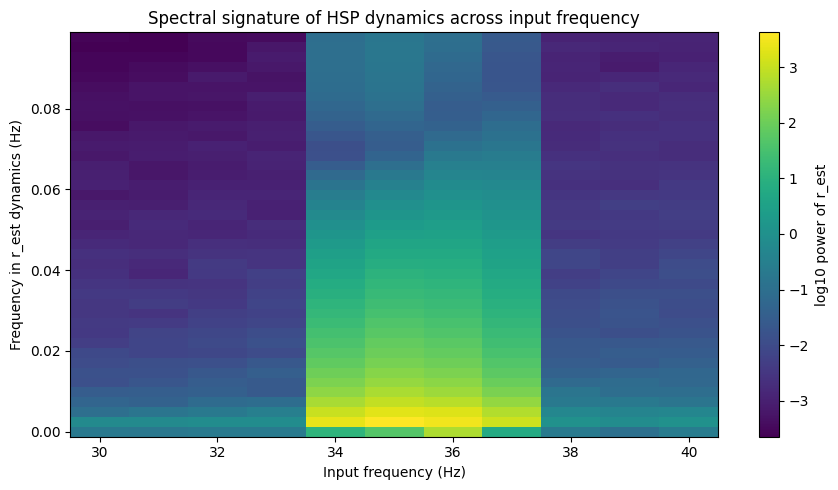

In [32]:
X = sweep_regular["input_freqs_hz"]
Y = sweep_regular["spectral_freqs_hz"]
P = sweep_regular["power"]

plt.figure(figsize=(9, 5))

plt.pcolormesh(
    X,
    Y,
    np.log10(P + 1e-12),
    shading="auto"
)

plt.colorbar(label="log10 power of r_est")
plt.xlabel("Input frequency (Hz)")
plt.ylabel("Frequency in r_est dynamics (Hz)")
plt.title("Spectral signature of HSP dynamics across input frequency")
plt.tight_layout()
plt.show()

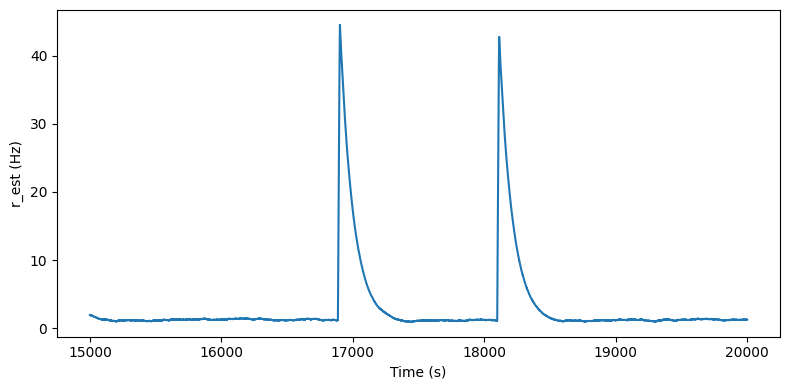

In [33]:
f_plot = 35.0

ts = sweep_regular["time_series"][f_plot]

plt.figure(figsize=(8, 4))
plt.plot(ts["t"], ts["r_est"])
plt.xlabel("Time (s)")
plt.ylabel("r_est (Hz)")
plt.tight_layout()
plt.show()

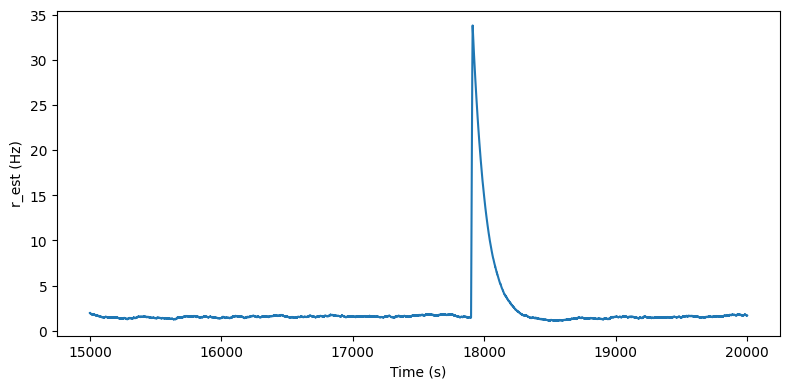

In [34]:
f_plot = 37.0

ts = sweep_regular["time_series"][f_plot]

plt.figure(figsize=(8, 4))
plt.plot(ts["t"], ts["r_est"])
plt.xlabel("Time (s)")
plt.ylabel("r_est (Hz)")
plt.tight_layout()
plt.show()

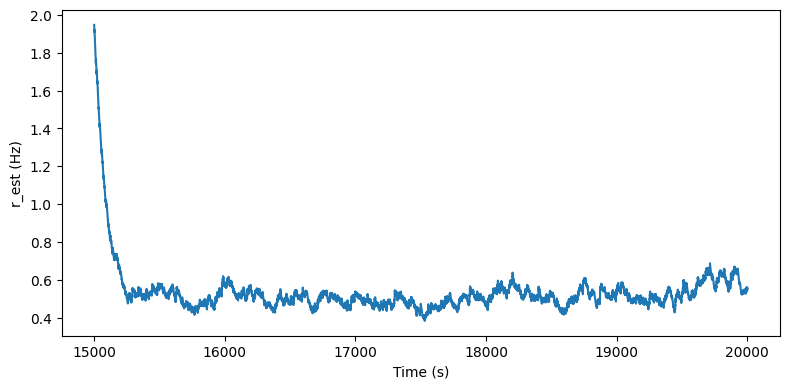

In [35]:
f_plot = 30.0

ts = sweep_regular["time_series"][f_plot]

plt.figure(figsize=(8, 4))
plt.plot(ts["t"], ts["r_est"])
plt.xlabel("Time (s)")
plt.ylabel("r_est (Hz)")
plt.tight_layout()
plt.show()

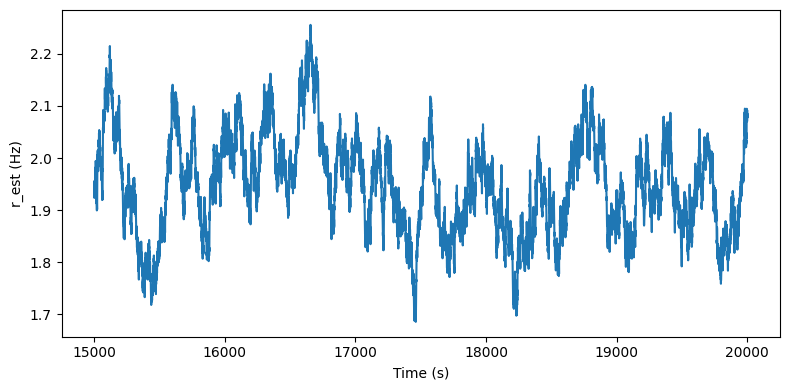

In [36]:
f_plot = 40.0

ts = sweep_regular["time_series"][f_plot]

plt.figure(figsize=(8, 4))
plt.plot(ts["t"], ts["r_est"])
plt.xlabel("Time (s)")
plt.ylabel("r_est (Hz)")
plt.tight_layout()
plt.show()

In [37]:
f_plot = 27.5

ts = sweep_regular["time_series"][f_plot]

plt.figure(figsize=(8, 4))
plt.plot(ts["t"], ts["r_est"])
plt.xlabel("Time (s)")
plt.ylabel("r_est (Hz)")
plt.tight_layout()
plt.show()

KeyError: 27.5

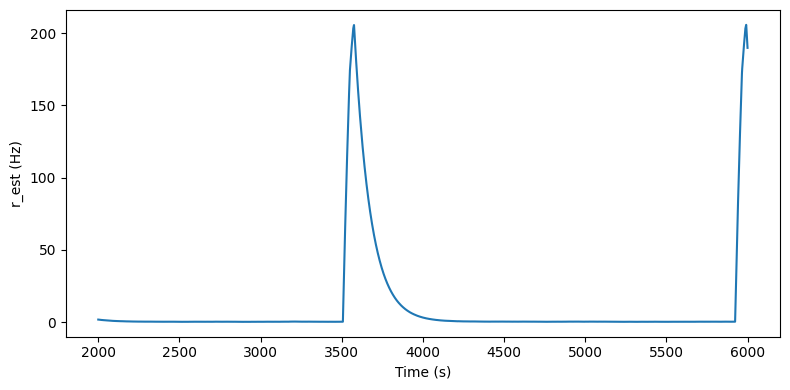

In [20]:
f_plot = 26.0

ts = sweep_regular["time_series"][f_plot]

plt.figure(figsize=(8, 4))
plt.plot(ts["t"], ts["r_est"])
plt.xlabel("Time (s)")
plt.ylabel("r_est (Hz)")
plt.tight_layout()
plt.show()

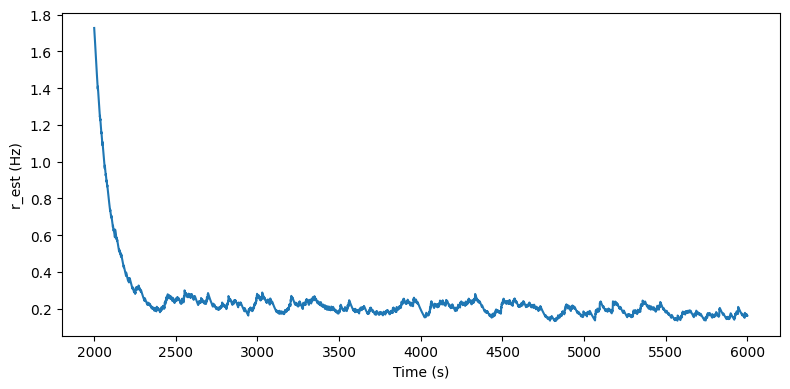

In [21]:
f_plot = 25.5

ts = sweep_regular["time_series"][f_plot]

plt.figure(figsize=(8, 4))
plt.plot(ts["t"], ts["r_est"])
plt.xlabel("Time (s)")
plt.ylabel("r_est (Hz)")
plt.tight_layout()
plt.show()

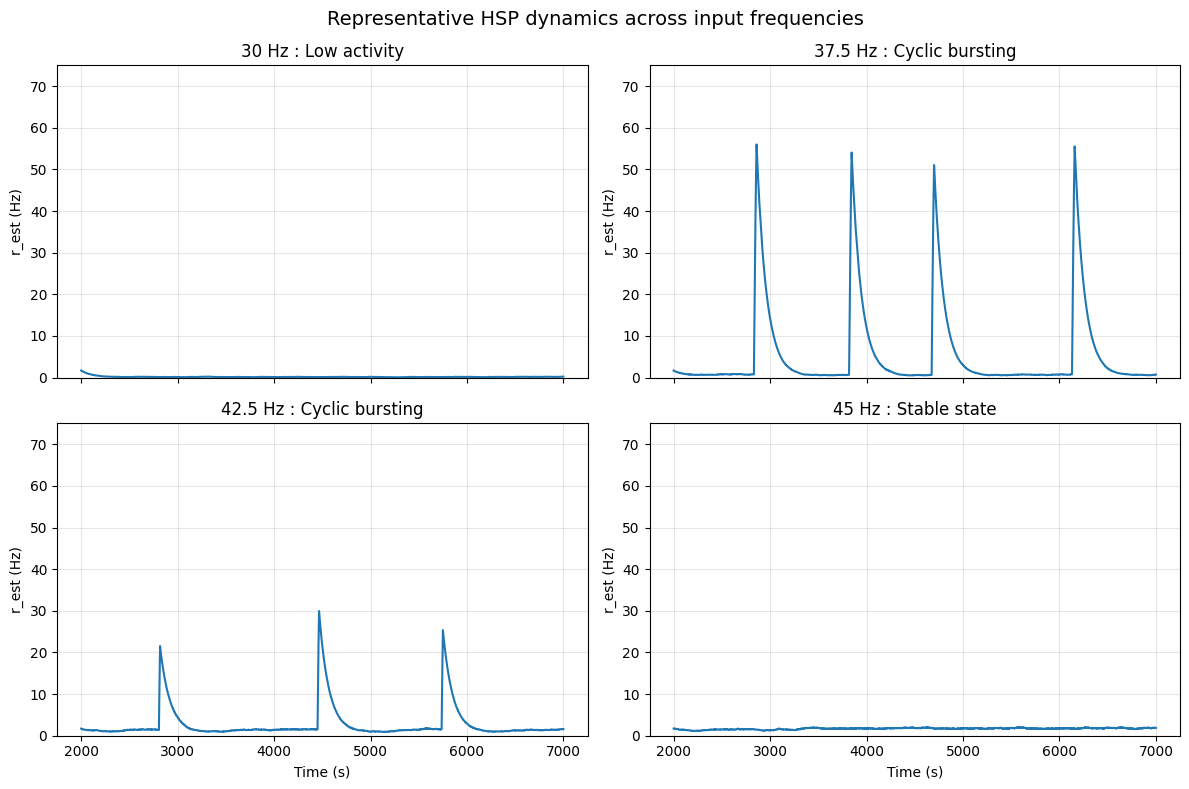

In [57]:
show_freqs = [30.0, 37.5, 42.5, 45.0]


fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True
)

axes = axes.flatten()

titles = {
    30.0: "30 Hz : Low activity",
    37.5: "37.5 Hz : Cyclic bursting",#Cyclic bursting
    42.5: "42.5 Hz : Cyclic bursting",
    45.0: "45 Hz : Stable state"
}

for ax, f in zip(axes, show_freqs):

    ts = sweep_regular["time_series"][f]

    mask = ts["t"] >= 2000

    ax.plot(
        ts["t"][mask],
        ts["r_est"][mask],
        lw=1.5
    )

    ax.set_title(titles[f])
    ax.set_ylabel("r_est (Hz)")
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 75) #220

axes[2].set_xlabel("Time (s)")
axes[3].set_xlabel("Time (s)")

plt.suptitle(
    "Representative HSP dynamics across input frequencies",
    fontsize=14
)

plt.tight_layout()
plt.show()

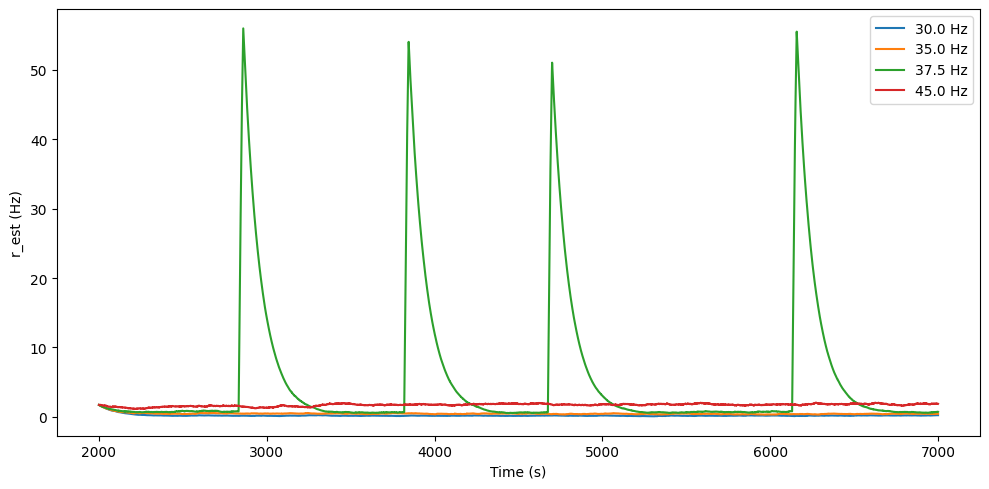

In [53]:
freqs = [30.0, 35.0, 37.5, 45.0]

plt.figure(figsize=(10,5))

for f in freqs:
    ts = sweep_regular["time_series"][f]

    mask = ts["t"] >= 2000

    plt.plot(
        ts["t"][mask],
        ts["r_est"][mask],
        label=f"{f} Hz"
    )

plt.xlabel("Time (s)")
plt.ylabel("r_est (Hz)")
plt.legend()
plt.tight_layout()
plt.show()

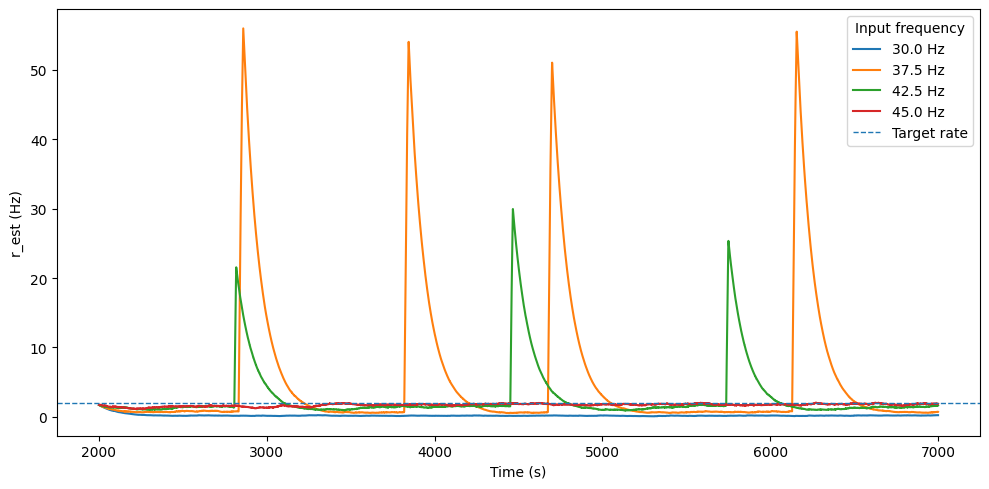

In [58]:
import matplotlib.pyplot as plt

freqs = [30.0, 37.5, 42.5, 45.0]

plt.figure(figsize=(10, 5))

for f in freqs:
    ts = sweep_regular["time_series"][f]
    mask = ts["t"] >= 2000

    plt.plot(
        ts["t"][mask],
        ts["r_est"][mask],
        lw=1.5,
        label=f"{f} Hz"
    )
plt.axhline(2, linestyle="--", linewidth=1, label="Target rate")
plt.xlabel("Time (s)")
plt.ylabel("r_est (Hz)")
plt.legend(title="Input frequency")
plt.tight_layout()
plt.show()

In [47]:
import numpy as np
import matplotlib.pyplot as plt
import importlib, hsp_robustness, hsp_metrics
importlib.reload(hsp_robustness)
importlib.reload(hsp_metrics)

from hsp_metrics import (run_sweep_with_metrics, run_trajectory_capture,
                         interictal_complexity, seizure_burden)
from hsp_robustness import (aggregate_conditions, rate_control,
                            rate_matched_comparison, plot_seed_averaged,
                            plot_rate_control)


In [6]:
out = run_trajectory_capture(net, input_freq=30.0, run_time=5000,   # 30 Hz = cyclic
                             analysis_start_s=2000.0, Nablocker=True)
comp = interictal_complexity(out["spike_i"], out["spike_t"], out["n_neurons"],
                             out["t0"], out["t1"], bin_s=0.1, target_hz=2.0,
                             factor=4.0, tse_samples=20,
                             rng=np.random.default_rng(0))
burd = seizure_burden(out["t"], out["r_est_trace"], target_hz=2.0, factor=4.0)
print("interictal panel:", {k: round(v, 3) for k, v in comp.items()
                            if isinstance(v, float)})
print("burden:", {k: round(v, 4) for k, v in burd.items()})

Starting simulation at t=2. ks for a duration of 5. ks
136.601 s (2%) simulated in 10s, estimated 5m 56s remaining.
287.802 s (5%) simulated in 20s, estimated 5m 27s remaining.
0.445845 ks (8%) simulated in 30s, estimated 5m 6s remaining.
0.588196 ks (11%) simulated in 40s, estimated 5m 0s remaining.
0.742014 ks (14%) simulated in 50s, estimated 4m 47s remaining.
0.896769 ks (17%) simulated in 1m 0s, estimated 4m 35s remaining.
1.051466 ks (21%) simulated in 1m 10s, estimated 4m 23s remaining.
1.191671 ks (23%) simulated in 1m 20s, estimated 4m 16s remaining.
1.347533 ks (26%) simulated in 1m 30s, estimated 4m 4s remaining.
1.504808 ks (30%) simulated in 1m 40s, estimated 3m 52s remaining.
1.64963 ks (32%) simulated in 1m 50s, estimated 3m 43s remaining.
1.808398 ks (36%) simulated in 2m 0s, estimated 3m 32s remaining.
1.965512 ks (39%) simulated in 2m 10s, estimated 3m 21s remaining.
2.114173 ks (42%) simulated in 2m 20s, estimated 3m 11s remaining.
2.27363 ks (45%) simulated in 2m 30

INFO:numexpr.utils:NumExpr defaulting to 16 threads.


interictal panel: {'H_joint': -66.525, 'H_marginal_sum': -66.513, 'multi_information': 0.012, 'tse_complexity': 0.195, 'lzc': 0.997, 'mean_rate_hz': 0.153, 'active_frac': 0.015, 'count_entropy_bits': 2.275, 'interictal_fraction': 1.0}
burden: {'ictal_fraction': 0.0, 'n_bursts': 0, 'burst_rate_hz': 0.0, 'mean_overshoot': 0.0, 'lf_power': 0.0225}


In [49]:
freqs = np.arange(30, 40, 1.0)          # adjust resolution as needed
common = dict(run_time_s=5000.0, analysis_start_s=15000.0,
              bin_s=0.1, target_hz=2.0, factor=4.0, tse_samples=20)

sweeps = {}
sweeps["normal"]    = run_sweep_with_metrics(net, freqs, condition="normal",    **common)
sweeps["nablocker"] = run_sweep_with_metrics(net, freqs, condition="nablocker", **common)
sweeps["benzo"]     = run_sweep_with_metrics(net, freqs, condition="benzo",     **common)
# (optional) save so you don't recompute:
np.save("sweeps.npy", sweeps, allow_pickle=True)

[normal] input = 30.00 Hz
Starting simulation at t=15. ks for a duration of 5. ks
134.924 s (2%) simulated in 10s, estimated 6m 28s remaining.
284.75 s (5%) simulated in 20s, estimated 5m 44s remaining.
0.435185 ks (8%) simulated in 30s, estimated 5m 23s remaining.
0.586465 ks (11%) simulated in 40s, estimated 5m 7s remaining.
0.716513 ks (14%) simulated in 50s, estimated 5m 3s remaining.
0.87376 ks (17%) simulated in 1m 0s, estimated 4m 47s remaining.
1.028596 ks (20%) simulated in 1m 10s, estimated 4m 33s remaining.
1.160671 ks (23%) simulated in 1m 20s, estimated 4m 27s remaining.
1.317188 ks (26%) simulated in 1m 30s, estimated 4m 14s remaining.
1.473336 ks (29%) simulated in 1m 40s, estimated 4m 1s remaining.
1.620523 ks (32%) simulated in 1m 51s, estimated 3m 53s remaining.
1.776705 ks (35%) simulated in 2m 1s, estimated 3m 41s remaining.
1.933328 ks (38%) simulated in 2m 11s, estimated 3m 29s remaining.
2.087799 ks (41%) simulated in 2m 21s, estimated 3m 18s remaining.
2.220672 

INFO:numexpr.utils:NumExpr defaulting to 16 threads.


[normal] input = 31.00 Hz
Starting simulation at t=15. ks for a duration of 5. ks
129.66 s (2%) simulated in 10s, estimated 6m 16s remaining.
282.659 s (5%) simulated in 20s, estimated 5m 34s remaining.
0.438607 ks (8%) simulated in 30s, estimated 5m 12s remaining.
0.575541 ks (11%) simulated in 40s, estimated 5m 7s remaining.
0.733507 ks (14%) simulated in 50s, estimated 4m 51s remaining.
0.890744 ks (17%) simulated in 1m 0s, estimated 4m 37s remaining.
1.04753 ks (20%) simulated in 1m 10s, estimated 4m 24s remaining.
1.181003 ks (23%) simulated in 1m 20s, estimated 4m 19s remaining.
1.337434 ks (26%) simulated in 1m 30s, estimated 4m 6s remaining.
1.495493 ks (29%) simulated in 1m 40s, estimated 3m 54s remaining.
1.632783 ks (32%) simulated in 1m 50s, estimated 3m 47s remaining.
1.789037 ks (35%) simulated in 2m 0s, estimated 3m 35s remaining.
1.942631 ks (38%) simulated in 2m 10s, estimated 3m 25s remaining.
2.075556 ks (41%) simulated in 2m 20s, estimated 3m 17s remaining.
2.23242 

In [50]:
np.save("sweeps.npy", sweeps, allow_pickle=True)

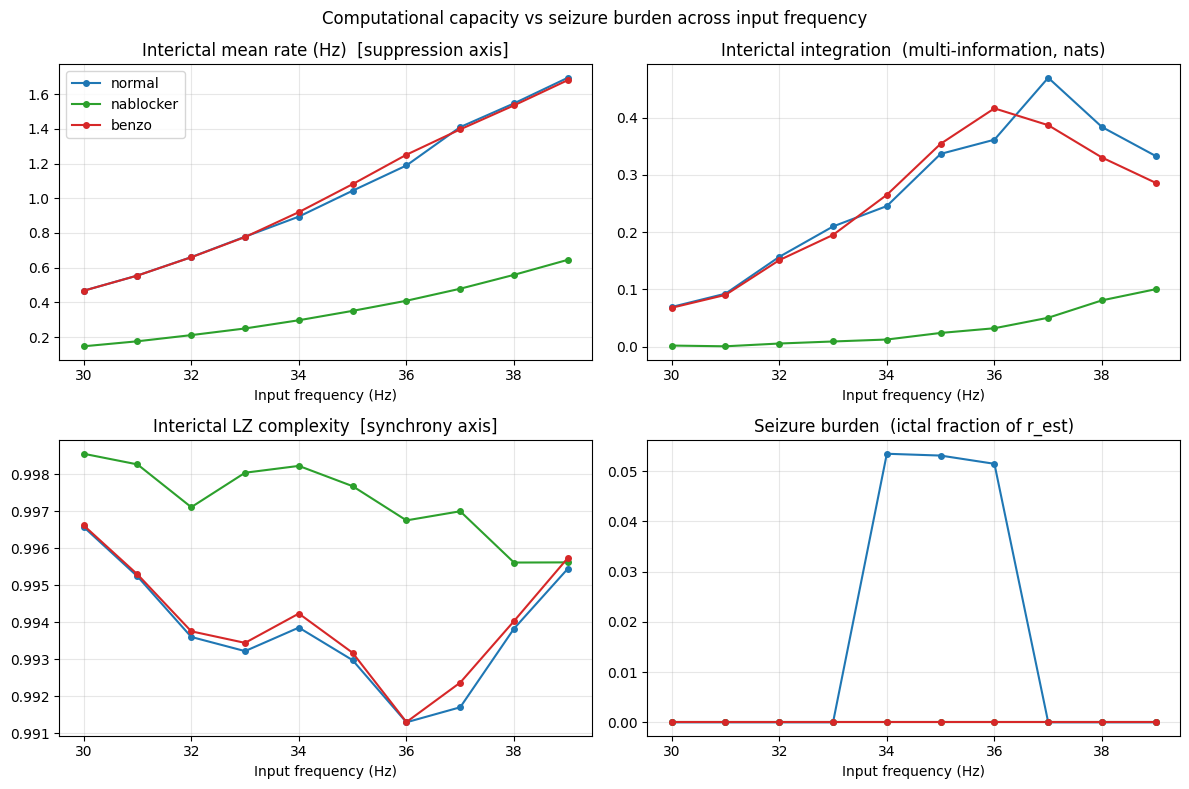

In [51]:
colors = {"normal": "tab:blue", "nablocker": "tab:green", "benzo": "tab:red"}
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
panels = [("mean_rate_hz",  "Interictal mean rate (Hz)  [suppression axis]"),
          ("multi_information", "Interictal integration  (multi-information, nats)"),
          ("lzc",           "Interictal LZ complexity  [synchrony axis]"),
          ("ictal_fraction","Seizure burden  (ictal fraction of r_est)")]
for a, (key, title) in zip(ax.ravel(), panels):
    for cond, sw in sweeps.items():
        a.plot(sw["input_freqs_hz"], sw[key], "-o", ms=4,
               color=colors[cond], label=cond)
    a.set_title(title); a.set_xlabel("Input frequency (Hz)"); a.grid(alpha=.3)
ax[0, 0].legend()
fig.suptitle("Computational capacity vs seizure burden across input frequency")
fig.tight_layout(); plt.show()

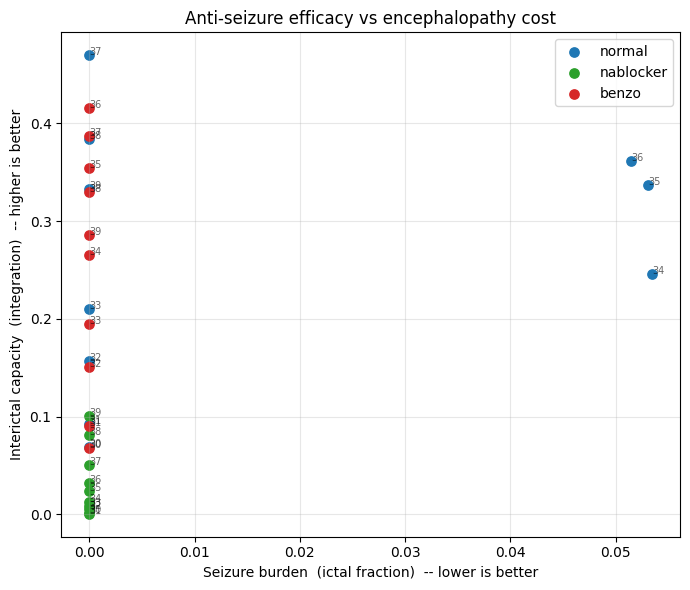

In [52]:
fig, axp = plt.subplots(figsize=(7, 6))
for cond, sw in sweeps.items():
    x = sw["ictal_fraction"]
    y = sw["multi_information"]           # try also "mean_rate_hz" or "lzc"
    axp.scatter(x, y, c=colors[cond], label=cond, s=45)
    for f, xi, yi in zip(sw["input_freqs_hz"], x, y):
        axp.annotate(f"{f:.0f}", (xi, yi), fontsize=7, alpha=.6)
axp.set_xlabel("Seizure burden  (ictal fraction)  -- lower is better")
axp.set_ylabel("Interictal capacity  (integration)  -- higher is better")
axp.set_title("Anti-seizure efficacy vs encephalopathy cost")
axp.grid(alpha=.3); axp.legend()
fig.tight_layout(); plt.show()

Starting simulation at t=2. ks for a duration of 5. ks
110.819 s (2%) simulated in 10s, estimated 7m 21s remaining.
211.15 s (4%) simulated in 20s, estimated 7m 34s remaining.
0.327318 ks (6%) simulated in 30s, estimated 7m 8s remaining.
0.432328 ks (8%) simulated in 40s, estimated 7m 3s remaining.
0.524596 ks (10%) simulated in 50s, estimated 7m 7s remaining.
0.634817 ks (12%) simulated in 1m 0s, estimated 6m 53s remaining.
0.749595 ks (14%) simulated in 1m 10s, estimated 6m 37s remaining.
0.837625 ks (16%) simulated in 1m 20s, estimated 6m 38s remaining.
0.913963 ks (18%) simulated in 1m 30s, estimated 6m 42s remaining.
1.006393 ks (20%) simulated in 1m 40s, estimated 6m 37s remaining.
1.110043 ks (22%) simulated in 1m 50s, estimated 6m 25s remaining.
1.204135 ks (24%) simulated in 2m 0s, estimated 6m 18s remaining.
1.314604 ks (26%) simulated in 2m 10s, estimated 6m 4s remaining.
1.41975 ks (28%) simulated in 2m 20s, estimated 5m 53s remaining.
1.509115 ks (30%) simulated in 2m 30s,

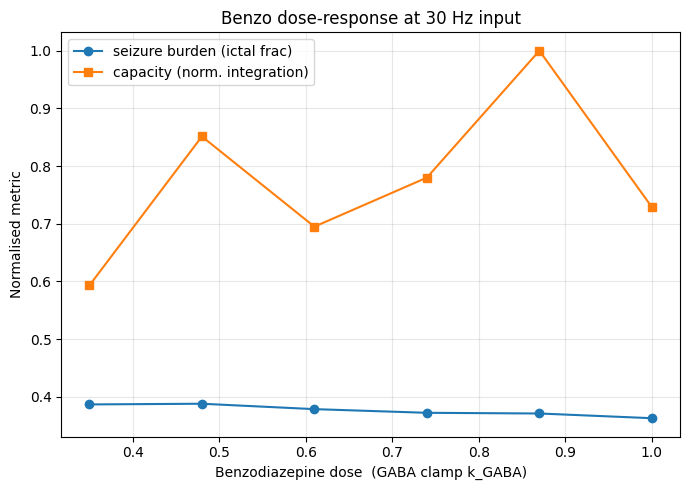

In [11]:
f_seizure = 30.0     # pick from your spectrogram's bright band for that condition
benzo_doses = np.linspace(0.35, 1.0, 6)   # k_GABA clamp: baseline .. maximal
rows = []
for d in benzo_doses:
    o = run_trajectory_capture(net, input_freq=f_seizure, run_time=5000,
                               analysis_start_s=2000.0, benzo=True, benzo_kGABA=d)
    c = interictal_complexity(o["spike_i"], o["spike_t"], o["n_neurons"],
                              o["t0"], o["t1"], bin_s=0.1, target_hz=2.0,
                              factor=4.0, tse_samples=20,
                              rng=np.random.default_rng(0))
    b = seizure_burden(o["t"], o["r_est_trace"], target_hz=2.0, factor=4.0)
    rows.append((d, b["ictal_fraction"], c.get("multi_information", np.nan),
                 c.get("mean_rate_hz", np.nan)))
rows = np.array(rows)

fig, axd = plt.subplots(figsize=(7, 5))
axd.plot(rows[:, 0], rows[:, 1], "-o", label="seizure burden (ictal frac)")
axd.plot(rows[:, 0], rows[:, 2] / np.nanmax(rows[:, 2]), "-s",
         label="capacity (norm. integration)")
axd.set_xlabel("Benzodiazepine dose  (GABA clamp k_GABA)")
axd.set_ylabel("Normalised metric")
axd.set_title(f"Benzo dose-response at {f_seizure:.0f} Hz input")
axd.grid(alpha=.3); axd.legend()
fig.tight_layout(); plt.show()
# Repeat with Nablocker=True and dose=na_vthr_mV (e.g. np.linspace(-50,-46,5))
# to compare drug classes -- the email's "predictions for several medication classes".

# seed averaging


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from hsp_robustness import (aggregate_conditions, rate_control,
                            rate_matched_comparison, plot_seed_averaged,
                            plot_rate_control)

In [13]:
freqs = np.arange(26, 45, 2.0)
seeds = (101, 202, 303, 404, 505, 606, 707, 808, 909, 1010)   # 10 seeds
 
common = dict(run_time_s=5000.0, analysis_start_s=2000.0,
              bin_s=0.1, target_hz=2.0, factor=4.0, tse_samples=20)
 
agg = aggregate_conditions(net, freqs,
                           conditions=("normal", "nablocker", "benzo"),
                           seeds=seeds, checkpoint_dir="hsp_ckpt", **common)
np.save("agg_seedavg.npy", agg, allow_pickle=True)   

[normal] input = 26.00 Hz
Starting simulation at t=2. ks for a duration of 5. ks
125.808 s (2%) simulated in 10s, estimated 6m 27s remaining.
267.32 s (5%) simulated in 20s, estimated 5m 54s remaining.
0.410443 ks (8%) simulated in 30s, estimated 5m 35s remaining.
0.542652 ks (10%) simulated in 40s, estimated 5m 29s remaining.
0.69118 ks (13%) simulated in 50s, estimated 5m 12s remaining.
0.830844 ks (16%) simulated in 1m 0s, estimated 5m 1s remaining.
0.927703 ks (18%) simulated in 1m 10s, estimated 5m 7s remaining.
1.047305 ks (20%) simulated in 1m 20s, estimated 5m 2s remaining.
1.174391 ks (23%) simulated in 1m 30s, estimated 4m 53s remaining.
1.304116 ks (26%) simulated in 1m 40s, estimated 4m 43s remaining.
1.419241 ks (28%) simulated in 1m 50s, estimated 4m 38s remaining.
1.544474 ks (30%) simulated in 2m 0s, estimated 4m 28s remaining.
1.67571 ks (33%) simulated in 2m 10s, estimated 4m 18s remaining.
1.799675 ks (35%) simulated in 2m 20s, estimated 4m 9s remaining.
1.895401 ks 

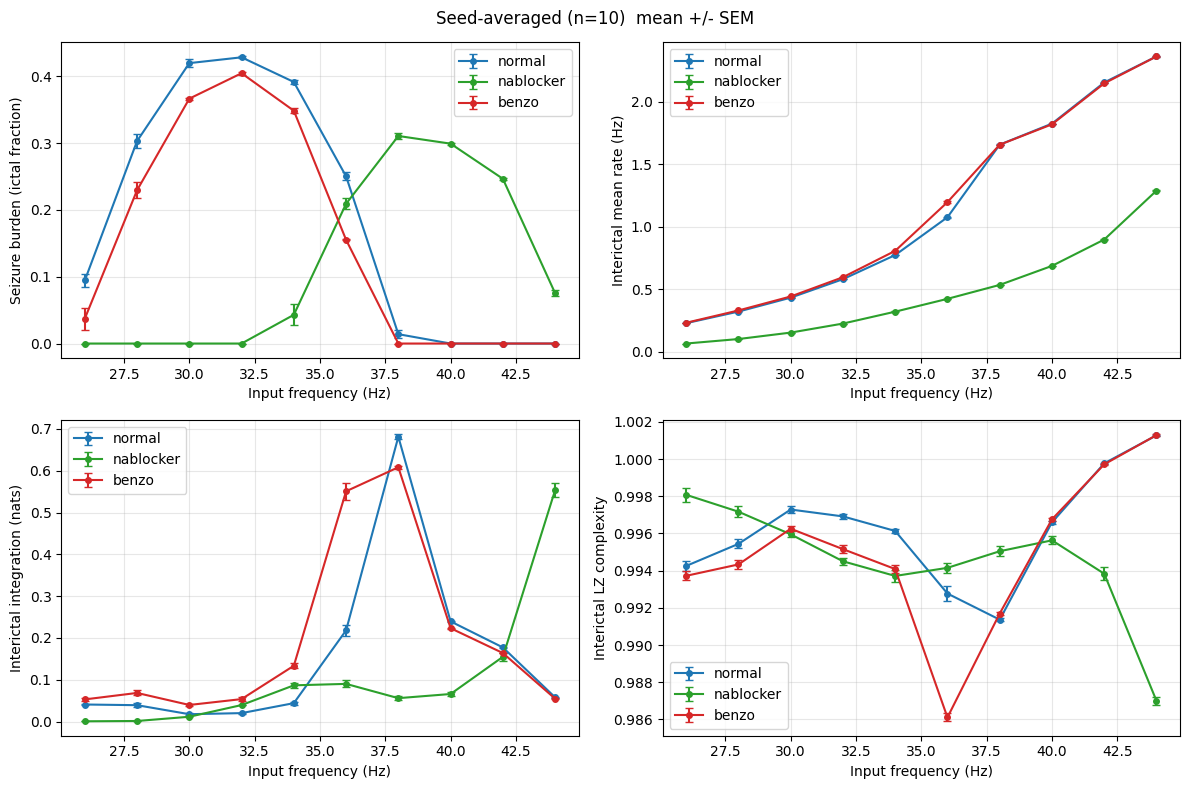

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
panels = [("ictal_fraction",    "Seizure burden (ictal fraction)"),
          ("mean_rate_hz",      "Interictal mean rate (Hz)"),
          ("multi_information", "Interictal integration (nats)"),
          ("lzc",               "Interictal LZ complexity")]
for a, (key, lab) in zip(ax.ravel(), panels):
    plot_seed_averaged(agg, key, ax=a, ylabel=lab)
fig.suptitle(f"Seed-averaged (n={len(seeds)})  mean +/- SEM")
fig.tight_layout(); plt.show()

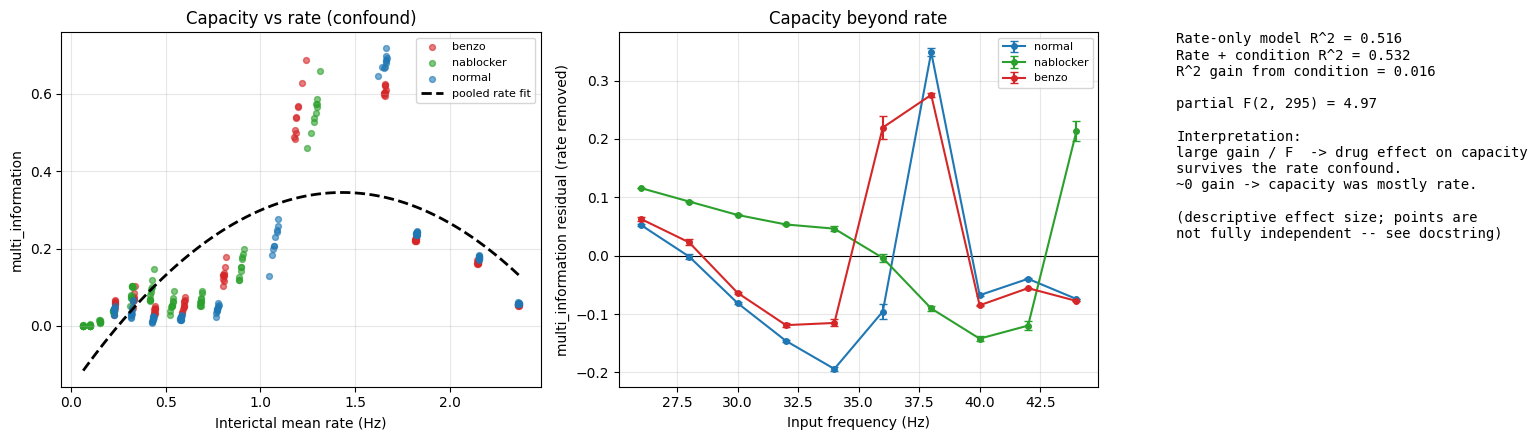

R^2 (rate only)      = 0.516
R^2 (rate+condition) = 0.532
R^2 gain from drug   = 0.016
partial F(2,295) = 4.97


In [15]:
rc = rate_control(agg, capacity="multi_information", rate="mean_rate_hz",
                  rate_degree=2)
fig = plot_rate_control(rc, agg); plt.show()
print(f"R^2 (rate only)      = {rc['r2_rate']:.3f}")
print(f"R^2 (rate+condition) = {rc['r2_full']:.3f}")
print(f"R^2 gain from drug   = {rc['r2_gain']:.3f}")
print(f"partial F({rc['df1']},{rc['df2']}) = {rc['partial_F']:.2f}")

In [20]:
import numpy as np, matplotlib.pyplot as plt
import importlib, hsp_robustness
importlib.reload(hsp_robustness)
from hsp_robustness import (capacity_model_ladder, edge_align,
                            find_seizure_edge, plot_edge_aligned)
 
# --- Cell E1: nested model ladder ---------------------------------------------
# Diagnoses WHY the offset-only rate_control reported a small F: your drug
# effect is a sideways shift, not an offset. Watch where R^2 jumps.
ladder = capacity_model_ladder(agg, capacity="multi_information",
                               rate="mean_rate_hz", freq_degree=2)
print(f"{'model':20s}{'R^2':>8s}{'n_params':>10s}{'F vs prev':>12s}")
for name, d in ladder.items():
    F = d["partial_F_vs_prev"]
    Fs = "  --" if F is None or (isinstance(F, float) and np.isnan(F)) else f"{F:10.2f}"
    print(f"{name:20s}{d['r2']:8.3f}{d['n_params']:10d}{Fs:>12s}")

model                    R^2  n_params   F vs prev
M0_rate                0.516         3          --
M1_+offset             0.532         5        4.97
M2_+freq               0.773         7      155.29
M3_+interaction        0.882        11       66.34


Reading: 
M1_+offset barely beats M0_rate  -> condition is NOT an offset.

M2_+freq / M3_+interaction jump  -> the effect is in WHERE the curve sits (frequency) and how it shifts per drug (interaction).

normal     upper seizure edge = 36.3 Hz  (ok)
nablocker  upper seizure edge = 43.1 Hz  (ok)
benzo      upper seizure edge = 35.5 Hz  (ok)


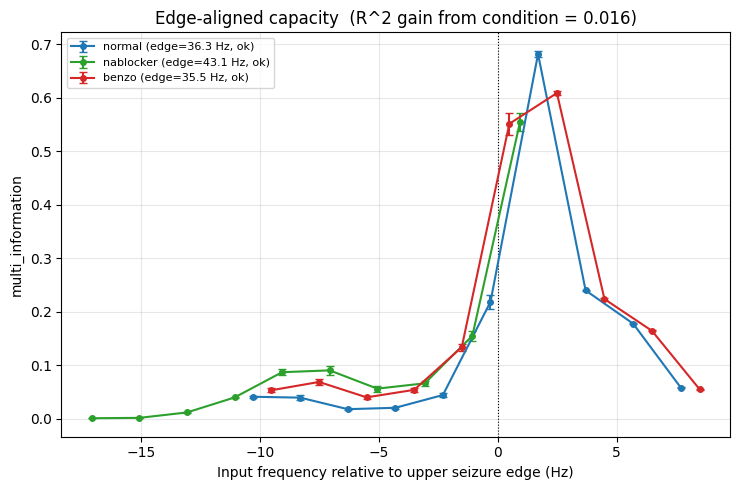


After aligning to each condition's seizure edge:
  R^2 (shape only)     = 0.254
  R^2 (+ condition)    = 0.270
  R^2 gain from drug   = 0.016


In [21]:
# --- Cell E2: seizure edges + edge-aligned capacity ---------------------------
for cond, agg_c in agg.items():
    e, status = find_seizure_edge(agg_c["freqs"], agg_c["mean"]["ictal_fraction"])
    print(f"{cond:10s} upper seizure edge = {e:.1f} Hz  ({status})")
 
ea = edge_align(agg, capacity="multi_information",
                burden="ictal_fraction", frac=0.5)
fig = plot_edge_aligned(ea); plt.show()
print(f"\nAfter aligning to each condition's seizure edge:")
print(f"  R^2 (shape only)     = {ea['r2_aligned']:.3f}")
print(f"  R^2 (+ condition)    = {ea['r2_full']:.3f}")
print(f"  R^2 gain from drug   = {ea['r2_gain']:.3f}")
# SMALL gain  -> curves overlap once aligned == "drugs translate the capacity
#                curve along input frequency; they do not change its height."
# LARGE gain  -> a drug genuinely raises/lowers capacity beyond relocating it.

In [22]:
# --- Cell E3: the honest headline check ---------------------------------------
# If E2 shows overlap, the defensible claim for the thesis/grant is:
#   "Anti-seizure manipulations relocate the input-frequency band in which the
#    network is both seizure-free and maximally coordinated, rather than
#    altering the peak level of coordination available."
# If a condition stands apart after alignment, name THAT condition as the one
# with a true capacity cost/benefit. Re-run E2 with capacity="lzc" to see
# whether the differentiation axis tells the same story.
ea_lz = edge_align(agg, capacity="lzc")
print(f"LZ-complexity edge-aligned R^2 gain = {ea_lz['r2_gain']:.3f}")

LZ-complexity edge-aligned R^2 gain = 0.061


In [7]:
import numpy as np, matplotlib.pyplot as plt
import importlib, hsp_capacity
importlib.reload(hsp_capacity)
from hsp_capacity import (make_input_signal, run_reservoir_probe,
                          capacity_report, capacity_sweep)

linear MC      = 0.48
nonlinear      = 0.42
IPC total      = 0.90
state rank / N = 100 / 100  (capacity bound)


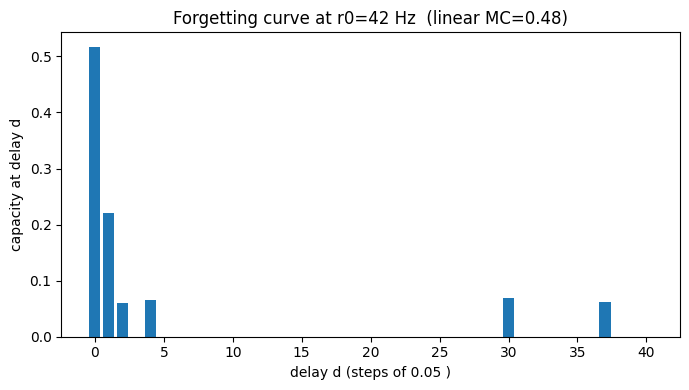

In [ ]:

 
# --- Cell C1: single probe at one operating point (sanity + forgetting curve) --
# adapt_s lets HSP settle at r0 BEFORE probing; keep small for the first run.
u = make_input_signal(n_steps=2000, seed=0)
out = run_reservoir_probe(net, u, step_s=0.05, r0_hz=42.0, amp_hz=15.0,
                          adapt_s=1000.0, freeze_hsp=True)   # 42 Hz ~ stable regime
rep = capacity_report(out["X"], out["u"], max_delay=40, nl_max_delay=10)
print(f"linear MC      = {rep['linear_mc']:.2f}")
print(f"nonlinear      = {rep['nonlinear']:.2f}")
print(f"IPC total      = {rep['ipc_total']:.2f}")
print(f"state rank / N = {rep['state_rank']} / {rep['n_state']}  (capacity bound)")
 
plt.figure(figsize=(7, 4))
plt.bar(rep["delays"], rep["forget_curve"], width=0.8)
plt.xlabel("delay d (steps of 0.05 )"); plt.ylabel("capacity at delay d")
plt.title(f"Forgetting curve at r0=42 Hz  (linear MC={rep['linear_mc']:.2f})")
plt.tight_layout(); plt.show()

In [ ]:
# --- Cell C2: capacity vs operating point, per condition ----------------------
# THE key experiment: does input-processing capacity peak where integration and
# the seizure edge sit? COST WARNING: one full probe (adapt + drive) per r0 per
# condition. Start with a coarse r0 grid and short adapt_s, scale up overnight.
r0_grid = np.arange(28, 45, 3.0)
cap = {}
for cond in ["normal", "nablocker", "benzo"]:
    cap[cond] = capacity_sweep(net, r0_grid, condition=cond, n_steps=2000,
                               step_s=0.05, amp_hz=15.0, adapt_s=3000.0,
                               max_delay=40, signal_seed=0)
# np.save("capacity_sweep.npy", cap, allow_pickle=True)
 
col = {"normal": "tab:blue", "nablocker": "tab:green", "benzo": "tab:red"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for key, title in zip(["linear_mc", "nonlinear", "ipc_total"],
                      ["Linear memory capacity", "Nonlinear capacity",
                       "Total IPC"]):
    for cond, c in cap.items():
        ax[{"linear_mc":0,"nonlinear":1,"ipc_total":2}[key]].plot(
            c["r0_hz"], c[key], "-o", color=col[cond], label=cond)
for a, t in zip(ax, ["Linear memory capacity","Nonlinear capacity","Total IPC"]):
    a.set_xlabel("Operating point r0 (Hz)"); a.set_title(t); a.grid(alpha=.3)
ax[0].set_ylabel("capacity (bits-equiv.)"); ax[0].legend()
fig.tight_layout(); plt.show()
 


In [ ]:
# --- Cell C3: the edge-of-chaos test ------------------------------------------
# Overlay total IPC against the seizure edge you already measured (from `agg`,
# the seed-averaged sweep). The prediction from the edge-of-chaos literature:
# capacity peaks AT the seizure edge, where interictal integration also peaked.
from hsp_robustness import find_seizure_edge
fig, ax = plt.subplots(figsize=(8, 5))
for cond, c in cap.items():
    ax.plot(c["r0_hz"], c["ipc_total"], "-o", color=col[cond], label=f"{cond} IPC")
    if 'agg' in dir() and cond in agg:
        edge, _ = find_seizure_edge(agg[cond]["freqs"],
                                    agg[cond]["mean"]["ictal_fraction"])
        ax.axvline(edge, color=col[cond], ls="--", alpha=.6)
ax.set_xlabel("Operating point / input frequency (Hz)")
ax.set_ylabel("Total IPC")
ax.set_title("Does processing capacity peak at the seizure edge? (dashed = edges)")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); plt.show()
# If the IPC peaks line up with the dashed seizure edges, you've shown the
# capacity claim DIRECTLY -- and that the drugs relocate the capacity peak,
# now measured with the field-standard metric rather than inferred from
# integration/LZ.
 
 


In [29]:
# =============================================================================
# FAST PATH (recommended): snapshot a settled interictal state, probe from it.
# Skips the per-point adaptation run. One snapshot per (condition, freq), 1 seed.
# =============================================================================
from hsp_capacity import (snapshot_interictal, probe_from_snapshot,
                          capacity_at_point)
 
# --- Cell C4: one fast point (snapshot -> probe), with the stability guard ----
rep = capacity_at_point(net, input_freq_hz=42.0, condition="normal",
                        n_steps=2000, max_delay=40,
                        snapshot_kw=dict(min_scan_s=2000.0, settle_s=400.0),
                        probe_kw=dict(amp_hz=15.0))
if not rep["found"]:
    print("no settled interictal phase found:", rep["status"])
else:
    print(f"snapshot at t={rep['t_snapshot']:.0f}s  "
          f"(k_AMPA={rep['k_AMPA_mean']:.3f}, k_GABA={rep['k_GABA_mean']:.3f})")
    print(f"linear MC={rep['linear_mc']:.2f}  nonlinear={rep['nonlinear']:.2f}  "
          f"IPC={rep['ipc_total']:.2f}")
    print(f"burst_during_probe = {rep['burst_during_probe']}  "
          "(True => frozen config went unstable; re-snapshot earlier in the "
          "low phase or treat as edge-of-stability)")
 


snapshot at t=4000s  (k_AMPA=0.349, k_GABA=0.651)
linear MC=0.20  nonlinear=0.99  IPC=1.19
burst_during_probe = False  (True => frozen config went unstable; re-snapshot earlier in the low phase or treat as edge-of-stability)


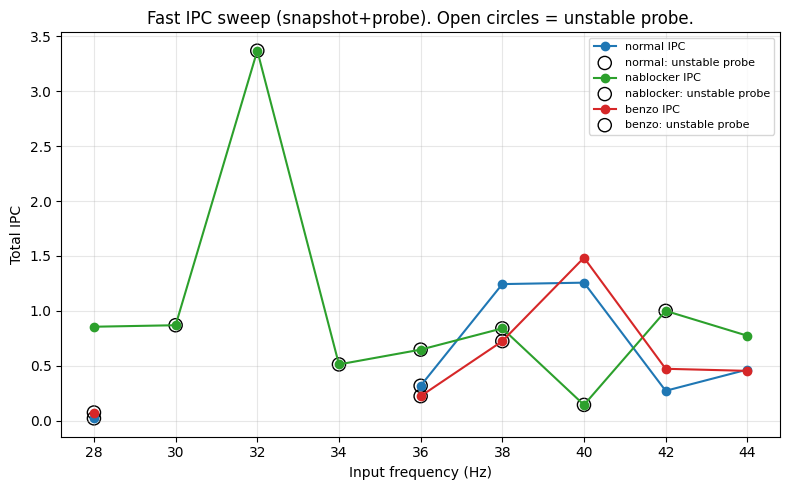

In [30]:
# --- Cell C5: fast edge-of-chaos sweep ----------------------------------------
# Same scientific question as C2/C3 but ~adapt-free. Each point = one snapshot
# + one short probe. Still benefits from cpp_standalone for the snapshot scan.
r0_grid = np.arange(28, 45, 2.0)
fast = {c: {"r0": [], "ipc": [], "lin": [], "nl": [], "burst": []}
        for c in ["normal", "nablocker", "benzo"]}
for cond in fast:
    for r0 in r0_grid:
        rep = capacity_at_point(net, float(r0), condition=cond, n_steps=2000,
                                max_delay=40,
                                snapshot_kw=dict(min_scan_s=2000.0, settle_s=400.0),
                                probe_kw=dict(amp_hz=15.0))
        fast[cond]["r0"].append(r0)
        if rep["found"]:
            fast[cond]["ipc"].append(rep["ipc_total"])
            fast[cond]["lin"].append(rep["linear_mc"])
            fast[cond]["nl"].append(rep["nonlinear"])
            fast[cond]["burst"].append(rep["burst_during_probe"])
        else:
            for k in ["ipc","lin","nl"]: fast[cond][k].append(np.nan)
            fast[cond]["burst"].append(True)
# np.save("capacity_fast.npy", fast, allow_pickle=True)
 
col = {"normal":"tab:blue","nablocker":"tab:green","benzo":"tab:red"}
fig, ax = plt.subplots(figsize=(8,5))
for cond, d in fast.items():
    r0=np.array(d["r0"]); ipc=np.array(d["ipc"]); burst=np.array(d["burst"])
    ax.plot(r0, ipc, "-o", color=col[cond], label=f"{cond} IPC")
    # mark points where the probe destabilised (interpret with caution)
    if burst.any():
        ax.scatter(r0[burst], ipc[burst], facecolors="none",
                   edgecolors="k", s=90, label=f"{cond}: unstable probe")
ax.set_xlabel("Input frequency (Hz)"); ax.set_ylabel("Total IPC")
ax.set_title("Fast IPC sweep (snapshot+probe). Open circles = unstable probe.")
ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
# Open circles flag points near the seizure edge where the frozen config went
# unstable under input -- exactly where MC is most delicate. Verify those with
# 2-3 snapshots taken at different interictal phases before trusting the value.
 

In [31]:
# =============================================================================
# AMPLITUDE CALIBRATION  -- run this BEFORE the C5 sweep.
# Fix the probe amplitude at normal / 40 Hz, then freeze it for ALL conditions
# and frequencies so cross-condition IPC stays comparable.
# Needs hsp_capacity.py + your built `net` with 'baseline' stored.
# =============================================================================
import numpy as np, matplotlib.pyplot as plt
import importlib, hsp_capacity
importlib.reload(hsp_capacity)
from hsp_capacity import calibrate_amplitude, suggest_amp
 
# --- Cell K1: sweep amplitude at one snapshot ---------------------------------
# Probes the SAME normal/40 Hz interictal snapshot at each amp (only amp varies).
# step_s=0.05 matches the memory horizon you found.
calib = calibrate_amplitude(net, input_freq_hz=40.0, condition="normal",
                            amps_hz=(2., 4., 6., 8., 12., 16.),
                            n_steps=1500, step_s=0.05, max_delay=40)
assert calib["found"], calib.get("status")
print(f"snapshot at t={calib['snapshot']['t_snapshot']:.0f}s  "
      f"(k_AMPA={calib['snapshot']['k_AMPA_mean']:.3f}, "
      f"k_GABA={calib['snapshot']['k_GABA_mean']:.3f})")
print(f"{'amp':>5} {'stable':>7} {'d0':>6} {'linMC':>7} {'nonlin':>7} "
      f"{'IPC':>6} {'maxRate':>8}")
for r in calib["results"]:
    print(f"{r['amp']:5.1f} {str(not r['burst']):>7} {r['d0']:6.2f} "
          f"{r['linear_mc']:7.2f} {r['nonlinear']:7.2f} {r['ipc']:6.2f} "
          f"{r['max_step_rate_hz']:8.1f}")
print(f"\nSUGGESTED amp = {calib['suggested_amp']}  ({calib['reason']})")
 


snapshot at t=4000s  (k_AMPA=0.450, k_GABA=0.549)
  amp  stable     d0   linMC  nonlin    IPC  maxRate
  2.0    True   0.13    0.00    0.28   0.28      4.8
  4.0    True   0.19    0.13    0.00   0.13      5.4
  6.0    True   0.25    0.15    0.30   0.44      5.8
  8.0    True   0.36    0.18    0.09   0.27      6.8
 12.0    True   0.45    0.57    0.63   1.21      8.4
 16.0    True   0.50    0.24    1.04   1.28     10.0

SUGGESTED amp = 16.0  (smallest stable amp reaching 95% of max d0 (0.50); IPC=1.28)


In [ ]:
# --- Cell K2: r_est response trace per amplitude ------------------------------
# Look for SMOOTH tracking of the input. A burst (sharp runaway far above the
# input-driven level) => amp too high. Input lost in baseline noise => too low.
res = calib["results"]
fig, axes = plt.subplots(len(res), 1, figsize=(10, 2.0*len(res)), sharex=True)
for ax, r in zip(np.atleast_1d(axes), res):
    # injected input rate, resampled onto the r_est time base for overlay
    step_t = np.arange(len(r["rates_hz"])) * r["step_s"]
    ax2 = ax.twinx()
    ax2.step(step_t, r["rates_hz"], where="post", color="0.7", lw=.8)
    ax2.set_ylabel("input rate (Hz)", color="0.6", fontsize=8)
    ax.plot(r["r_est_t"], r["r_est"], color="tab:blue", lw=1.2)
    flag = "  <-- UNSTABLE (burst)" if r["burst"] else ""
    ax.set_title(f"amp={r['amp']:.0f} Hz   d0={r['d0']:.2f}  IPC={r['ipc']:.2f}"
                 f"   max pop rate={r['max_step_rate_hz']:.0f} Hz{flag}",
                 fontsize=9, loc="left")
    ax.set_ylabel("r_est (Hz)")
    if r["amp"] == calib["suggested_amp"]:
        ax.patch.set_facecolor("#eef7ee")
np.atleast_1d(axes)[-1].set_xlabel("time since probe onset (s)")
fig.suptitle("r_est response vs injected input across probe amplitudes "
             "(green = suggested)")
fig.tight_layout(); plt.show()
 


In [ ]:
# --- Cell K3: capacity vs amplitude summary -----------------------------------
amps = np.array([r["amp"] for r in res])
fig, ax = plt.subplots(figsize=(7, 4.5))
for key, lab in [("d0","d0 capacity"), ("linear_mc","linear MC"),
                 ("nonlinear","nonlinear"), ("ipc","IPC total")]:
    ax.plot(amps, [r[key] for r in res], "-o", label=lab)
burst_amps = amps[[r["burst"] for r in res]]
for ba in burst_amps:
    ax.axvspan(ba-0.4, ba+0.4, color="red", alpha=.08)
if calib["suggested_amp"] is not None:
    ax.axvline(calib["suggested_amp"], color="green", ls="--",
               label=f"suggested = {calib['suggested_amp']}")
ax.set_xlabel("probe amplitude (Hz)"); ax.set_ylabel("capacity")
ax.set_title("Capacity vs amplitude (red band = unstable probe)")
ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
 


In [ ]:
# --- Cell K4: LOCK IT IN ------------------------------------------------------
# Set this once and pass amp_hz=AMP_STAR everywhere in the C5 sweep / capacity_at_point.
AMP_STAR = calib["suggested_amp"]      # or override by eye from the traces above
print(f"Using AMP_STAR = {AMP_STAR} Hz for all conditions and frequencies.")
# Example: capacity_at_point(net, f, condition=c, probe_kw=dict(amp_hz=AMP_STAR), ...)

WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([41.64354025, 37.23744057, 34.49168229, ..., 34.29801376,
       36.49183539, 37.60634357]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


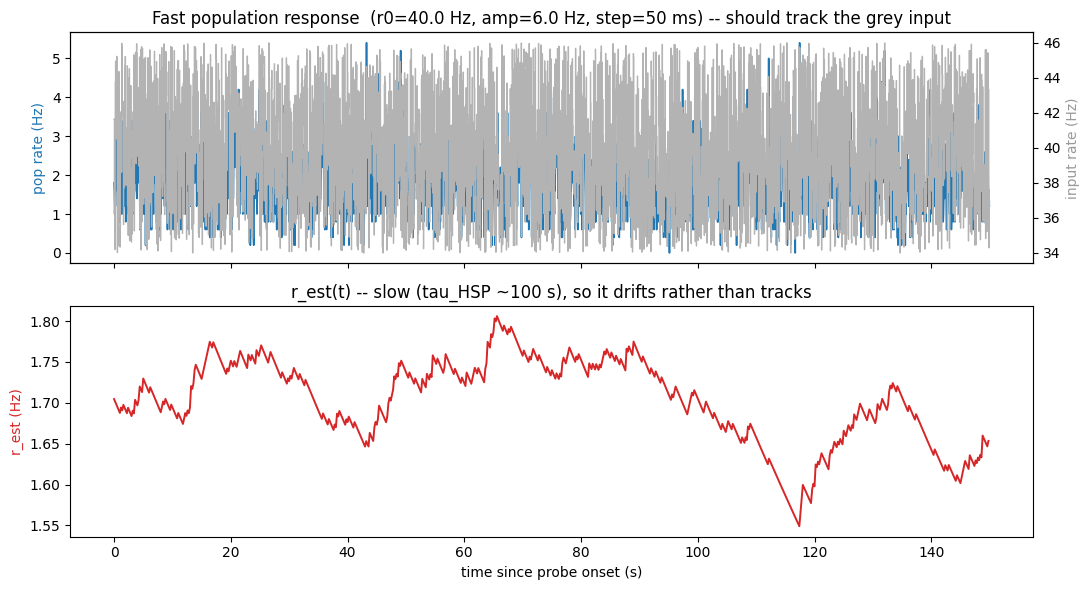

injected rate range : 34.0-46.0 Hz
pop rate range      : 0.0-5.4 Hz
r_est range         : 1.55-1.81 Hz


In [11]:
# =============================================================================
# Minimal test: does adding a signal on top of the Poisson input reach the net?
# Restores baseline, drives inp.rates = r0 + amp*u(t), plots the response.
# Needs your built `net` with 'baseline' stored.
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
from brian2 import Hz, second

# --- settings -----------------------------------------------------------------
r0_hz   = 40.0     # your normal input rate (set to whatever "normal" drive is)
amp_hz  = 6.0      # signal amplitude added on top
step_s  = 0.05     # each input value held this long
n_steps = 3000      # 400 probe length = n_steps * step_s = 20 s
seed    = 0

# --- restore the model at baseline --------------------------------------------
net.restore('baseline')
inp       = net['inp']
sp_E      = net['sp_exc']
r_est_mon = net['r_est']
_ns = globals().get('_MODEL_NS', None)
run_kw = dict(namespace=_ns) if _ns else {}

# --- build the signal: rate(t) = r0 + amp * u,  u ~ Uniform[-1,1] -------------
rng   = np.random.default_rng(seed)
u     = rng.uniform(-1.0, 1.0, size=n_steps)
rates = np.clip(r0_hz + amp_hz * u, 0.0, None)

t_start = float(net.t / second)          # mark probe onset

# --- drive the network one input value per step -------------------------------
for k in range(n_steps):
    inp.rates = rates[k] * Hz            
    net.run(step_s * second, **run_kw)

# --- pull r_est(t) (neuron 45) over the probe window --------------------------
tr = np.asarray(r_est_mon.t / second)
rr = np.asarray(r_est_mon.r_est[0] / Hz)
m  = tr >= t_start
t_re, r_re = tr[m] - t_start, rr[m]

# --- fast population rate from spikes (this is what actually shows tracking) ---
si = np.asarray(sp_E.i); st = np.asarray(sp_E.t / second)
n_E = int(net['P_E'].N)
edges = t_start + np.arange(n_steps + 1) * step_s
win = (st >= edges[0]) & (st < edges[-1])
counts, _ = np.histogram(st[win], bins=edges)
pop_rate = counts / (n_E * step_s)
t_pop = np.arange(n_steps) * step_s

# --- plot ---------------------------------------------------------------------
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# top: fast population rate vs injected input
ax[0].plot(t_pop, pop_rate, color="tab:blue", lw=1.2, label="population rate")
ax0b = ax[0].twinx()
ax0b.step(t_pop, rates, where="post", color="0.7", lw=0.9)
ax0b.set_ylabel("input rate (Hz)", color="0.6")
ax[0].set_ylabel("pop rate (Hz)", color="tab:blue")
ax[0].set_title(f"Fast population response  (r0={r0_hz} Hz, amp={amp_hz} Hz, "
                f"step={step_s*1000:.0f} ms) -- should track the grey input")

# bottom: r_est(t) as requested
ax[1].plot(t_re, r_re, color="tab:red", lw=1.4, label="r_est (neuron 45)")
ax[1].set_ylabel("r_est (Hz)", color="tab:red")
ax[1].set_xlabel("time since probe onset (s)")
ax[1].set_title("r_est(t) -- slow (tau_HSP ~100 s), so it drifts rather than tracks")

fig.tight_layout(); plt.show()

print(f"injected rate range : {rates.min():.1f}-{rates.max():.1f} Hz")
print(f"pop rate range      : {pop_rate.min():.1f}-{pop_rate.max():.1f} Hz")
print(f"r_est range         : {r_re.min():.2f}-{r_re.max():.2f} Hz")

# IPC


In [38]:
# =============================================================================
# PHASE-RESOLVED IPC + INTERVENTION COMPARISON
# Put hsp_phase.py next to hsp_capacity.py / hsp_metrics.py. Needs `net` built
# with 'baseline' stored, and a calibrated amplitude (AMP_STAR) + step_s.
# Tracks throughout: IPC, multi-information, E/I balance (rates + k's), power.
# =============================================================================
import numpy as np, matplotlib.pyplot as plt
import importlib, HSP_Phase
importlib.reload(HSP_Phase)
from HSP_Phase import (characterize_cycle, phase_resolved_capacity,
                       intervention_comparison)

AMP_STAR = 8.0        # from the amplitude calibration
STEP_S   = 0.05

import hsp_metrics, hsp_capacity
print('metrics  :', bool(getattr(hsp_metrics,  '_MODEL_NS', None)))
print('capacity :', bool(getattr(hsp_capacity, '_MODEL_NS', None)))

metrics  : False
capacity : False


bursting=True  period=1975s  recovery=195s  cycle power=37.74
phase           IPC  linMC  multiI     E     I   E/I   power    kA    kG stable
post_ictal     0.72   0.27    0.00  0.90  0.05 17.94   0.002  0.12  0.88   True
mid            0.45   0.13    0.00  1.04  0.15  6.81   0.000  0.52  0.48   True
pre_ictal      0.68   0.15    0.14  1.21  0.61  1.98   0.000  0.90  0.10   True


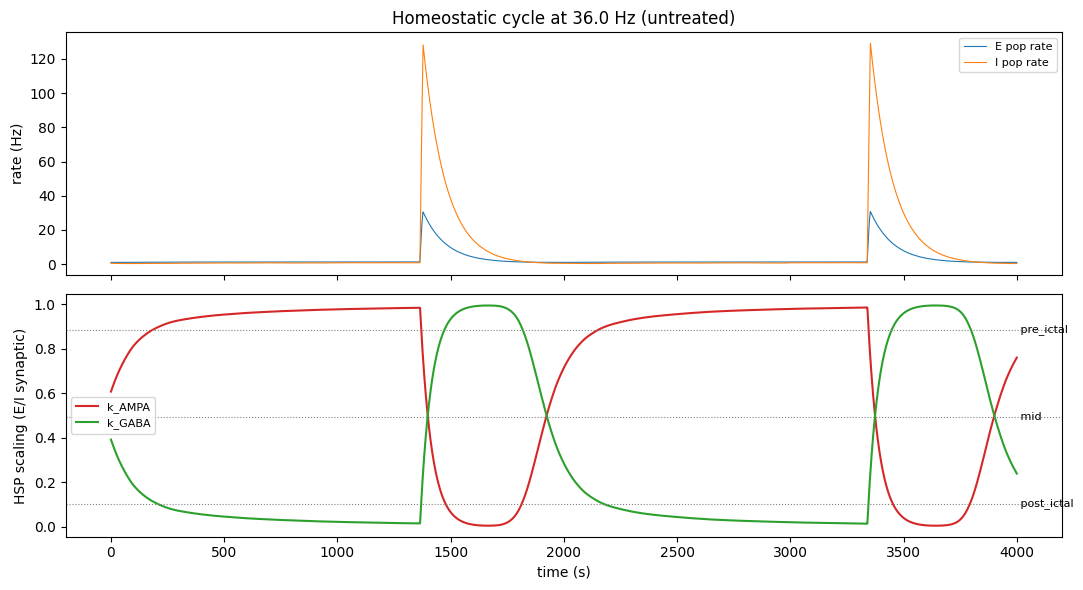

In [39]:
# --- Cell P1: does HSP keep IPC up across the cycle? --------------------------
# Pick a BURSTING operating point (so post-ictal / mid / pre-ictal exist).
f_seizure = 36.0      # a frequency where the untreated network seizes
prc = phase_resolved_capacity(net, f_seizure, drug={}, amp_hz=AMP_STAR,
                              step_s=STEP_S, n_steps=2000)

cyc = prc["cycle"]
print(f"bursting={cyc['is_bursting']}  period={cyc['period_s']:.0f}s  "
      f"recovery={cyc['recovery_s']:.0f}s  cycle power={cyc['cycle_lf_power']:.2f}")
print(f"{'phase':12}{'IPC':>7}{'linMC':>7}{'multiI':>8}{'E':>6}{'I':>6}"
      f"{'E/I':>6}{'power':>8}{'kA':>6}{'kG':>6}{'stable':>7}")
for r in prc["rows"]:
    if not r.get("found"):
        print(f"{r['phase']:12} (not found: {r.get('status')})"); continue
    print(f"{r['phase']:12}{r['ipc_total']:7.2f}{r['linear_mc']:7.2f}"
          f"{r['multi_information']:8.2f}{r['E_rate']:6.2f}{r['I_rate']:6.2f}"
          f"{r['EI_ratio']:6.2f}{r['rest_power']:8.3f}{r['k_AMPA']:6.2f}"
          f"{r['k_GABA']:6.2f}{str(not r['burst_during_probe']):>7}")

# cycle trace with the three snapshot phases marked on k_AMPA
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(cyc["t"], cyc["rE"], color="tab:blue", lw=.8, label="E pop rate")
ax[0].plot(cyc["t"], cyc["rI"], color="tab:orange", lw=.8, label="I pop rate")
ax[0].set_ylabel("rate (Hz)"); ax[0].legend(fontsize=8); ax[0].set_title(
    f"Homeostatic cycle at {f_seizure} Hz (untreated)")
ax[1].plot(cyc["t"], cyc["k_AMPA"], color="tab:red", label="k_AMPA")
ax[1].plot(cyc["t"], cyc["k_GABA"], color="tab:green", label="k_GABA")
for r in prc["rows"]:
    if r.get("found"):
        ax[1].axhline(r["k_target"], ls=":", color="0.5", lw=.8)
        ax[1].text(cyc["t"][-1], r["k_target"], " "+r["phase"], fontsize=8, va="center")
ax[1].set_ylabel("HSP scaling (E/I synaptic)"); ax[1].set_xlabel("time (s)")
ax[1].legend(fontsize=8); fig.tight_layout(); plt.show()
# Read: how much IPC is lost post-ictally and whether it recovers by 'mid';
# 'pre_ictal' is where the probe most often destabilizes (near-edge), which is
# itself the point that HSP has to ride without losing computation.



bursting=False  period=nans  recovery=nans  cycle power=0.01
phase           IPC  linMC  multiI     E     I   E/I   power    kA    kG stable
steady         0.25   0.25    0.05  1.88  1.82  1.03   0.000  0.75  0.21   True


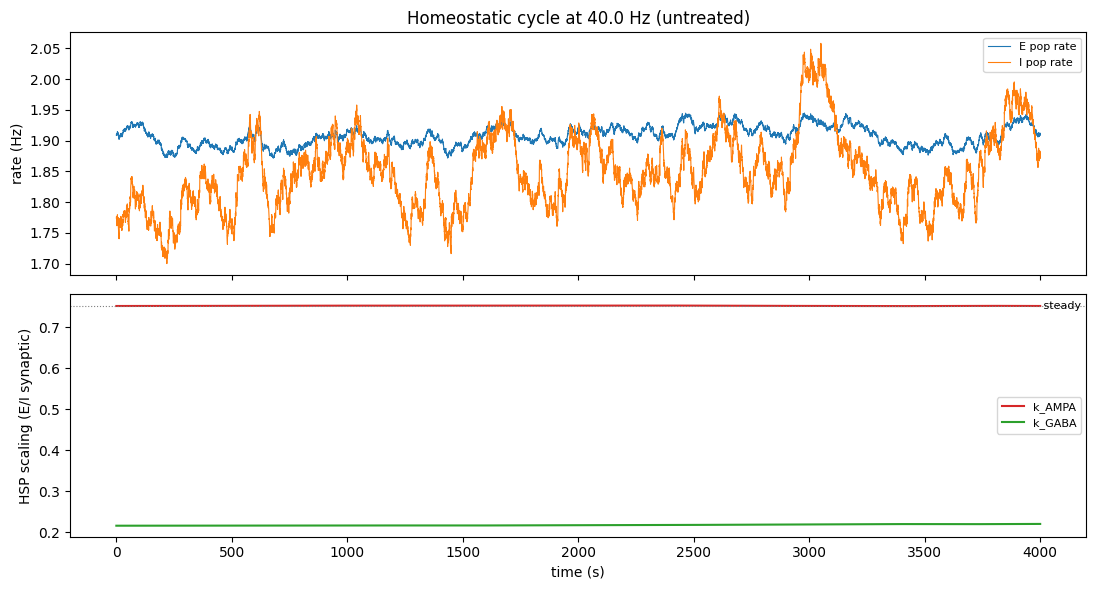

In [40]:
# --- Cell P1: does HSP keep IPC up across the cycle? --------------------------
# Pick a BURSTING operating point (so post-ictal / mid / pre-ictal exist).
f_seizure = 40.0      # a frequency where the untreated network seizes
prc = phase_resolved_capacity(net, f_seizure, drug={}, amp_hz=AMP_STAR,
                              step_s=STEP_S, n_steps=2000)

cyc = prc["cycle"]
print(f"bursting={cyc['is_bursting']}  period={cyc['period_s']:.0f}s  "
      f"recovery={cyc['recovery_s']:.0f}s  cycle power={cyc['cycle_lf_power']:.2f}")
print(f"{'phase':12}{'IPC':>7}{'linMC':>7}{'multiI':>8}{'E':>6}{'I':>6}"
      f"{'E/I':>6}{'power':>8}{'kA':>6}{'kG':>6}{'stable':>7}")
for r in prc["rows"]:
    if not r.get("found"):
        print(f"{r['phase']:12} (not found: {r.get('status')})"); continue
    print(f"{r['phase']:12}{r['ipc_total']:7.2f}{r['linear_mc']:7.2f}"
          f"{r['multi_information']:8.2f}{r['E_rate']:6.2f}{r['I_rate']:6.2f}"
          f"{r['EI_ratio']:6.2f}{r['rest_power']:8.3f}{r['k_AMPA']:6.2f}"
          f"{r['k_GABA']:6.2f}{str(not r['burst_during_probe']):>7}")

# cycle trace with the three snapshot phases marked on k_AMPA
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(cyc["t"], cyc["rE"], color="tab:blue", lw=.8, label="E pop rate")
ax[0].plot(cyc["t"], cyc["rI"], color="tab:orange", lw=.8, label="I pop rate")
ax[0].set_ylabel("rate (Hz)"); ax[0].legend(fontsize=8); ax[0].set_title(
    f"Homeostatic cycle at {f_seizure} Hz (untreated)")
ax[1].plot(cyc["t"], cyc["k_AMPA"], color="tab:red", label="k_AMPA")
ax[1].plot(cyc["t"], cyc["k_GABA"], color="tab:green", label="k_GABA")
for r in prc["rows"]:
    if r.get("found"):
        ax[1].axhline(r["k_target"], ls=":", color="0.5", lw=.8)
        ax[1].text(cyc["t"][-1], r["k_target"], " "+r["phase"], fontsize=8, va="center")
ax[1].set_ylabel("HSP scaling (E/I synaptic)"); ax[1].set_xlabel("time (s)")
ax[1].legend(fontsize=8); fig.tight_layout(); plt.show()
# Read: how much IPC is lost post-ictally and whether it recovers by 'mid';
# 'pre_ictal' is where the probe most often destabilizes (near-edge), which is
# itself the point that HSP has to ride without losing computation.




intervention       seizing  recov  seizPow   IPC  IPCret  multiI   E/I  score
Na-blocker           False    nan     0.00  1.03    1.00    0.00607.00  1.023
Na + low benzo       False    nan     0.00  0.17    1.00    0.01118.00  0.168
untreated             True    192    26.30  1.34    0.60    0.00 18.34  0.049
benzo (k=0.7)         True    198    35.06  0.89    0.68    0.01 13.78  0.025
benzo (k=1.0)         True    197    46.45  0.89    0.74    0.02  9.43  0.019


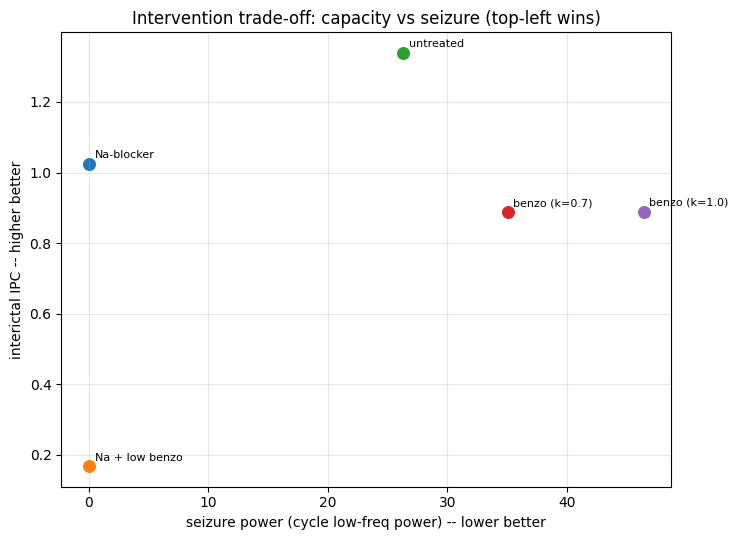

In [17]:
# --- Cell P2: compare interventions, including mixtures -----------------------
# Each intervention is a drug dict; a MIXTURE just sets several keys at once.
interventions = [
    {"name": "untreated",        "drug": {}},
    {"name": "benzo (k=0.7)",    "drug": {"benzo": True, "benzo_kGABA": 0.7}},
    {"name": "benzo (k=1.0)",    "drug": {"benzo": True, "benzo_kGABA": 1.0}},
    {"name": "Na-blocker",       "drug": {"na_blocker": True, "na_vthr_mV": -48,
                                          "na_refrac_ms": 3.0}},
    {"name": "Na + low benzo",   "drug": {"na_blocker": True, "na_vthr_mV": -48,
                                          "benzo": True, "benzo_kGABA": 0.7}},
]
summary = intervention_comparison(net, interventions, f_seizure,
                                  amp_hz=AMP_STAR, step_s=STEP_S, n_steps=2000)

print(f"\n{'intervention':18}{'seizing':>8}{'recov':>7}{'seizPow':>9}"
      f"{'IPC':>6}{'IPCret':>8}{'multiI':>8}{'E/I':>6}{'score':>7}")
for s in summary:                                   # already sorted best-first
    print(f"{s['name']:18}{str(s['is_bursting']):>8}{s['recovery_s']:7.0f}"
          f"{s['cycle_lf_power']:9.2f}{s['ipc_ref']:6.2f}{s['ipc_retained']:8.2f}"
          f"{s['multi_information']:8.2f}{s['EI_ratio']:6.2f}{s['tradeoff_score']:7.3f}")

# trade-off scatter: capacity vs seizure power (top-left = best)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for s in summary:
    ax.scatter(s["cycle_lf_power"], s["ipc_ref"], s=70)
    ax.annotate(s["name"], (s["cycle_lf_power"], s["ipc_ref"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("seizure power (cycle low-freq power) -- lower better")
ax.set_ylabel("interictal IPC -- higher better")
ax.set_title("Intervention trade-off: capacity vs seizure (top-left wins)")
ax.grid(alpha=.3); fig.tight_layout(); plt.show()
# The ranking column 'score' = IPC / (1 + seizure power): rewards preserved
# computation, penalizes seizure power. Mixtures can land in the top-left that
# single agents miss -- that's the "best mixture" result, if it exists.